# Aging and rejuvenating interventions in the mouse cerebellum

**Objective:** describe transcriptional aging in the mouse cerebellum, describe the effects of acute dietary restriction (aDR) and young mouse plasma (YMP), and explore whether each intervention opposes the aging changes.

- **Reference:** Hahn et al. (2023). **Data:** RSEM quantification (STAR alignments, GENCODE M39) of 27 runs, BioProjects PRJNA875066 (aging) and PRJNA946653 (interventions), read from the repo's `for_teammates/` folder.
- **Setup:** the team's common DESeq2 setup (agreed 20 November 2026), summarised in Section 3.
- **Run:** from this folder with the repo's pixi environment (R kernel `ir`): `pixi run jupyter nbconvert --to notebook --execute --inplace Script.ipynb`. Outputs go to `output/`. The first run downloads MSigDB release 2026.1 once (checksum-verified by `msigdbr`).
- **Scope:** three comparisons, each within its own cohort: aging (old vs young), aDR vs AL, YMP vs PBS. Never pooled across cohorts.

| Section | Question |
|---|---|
| 1 · Import and quality control | Which samples go into the analysis? |
| 2 · Exploratory analysis | Do samples group by experiment and condition? |
| 3 · Differential expression | Which genes change with age, aDR and YMP? |
| 4 · Pathways (Hallmark GSEA) | Which biological processes shift? |
| 5 · Aging vs interventions | Do aDR or YMP move aging genes in the opposite direction? |

In [1]:
# Packages, figure style and output folder
suppressPackageStartupMessages({
  library(DESeq2); library(apeglm); library(fgsea); library(msigdbr); library(ggrepel)
  library(tidyverse)   # loaded last, so dplyr's count/select/filter are not masked
})
options(jupyter.rich_display = FALSE, width = 140)
# Large text and tight margins in every figure
theme_set(theme_minimal(base_size = 40) +
  theme(panel.grid.minor = element_blank(), axis.text = element_text(colour = "#333333"), plot.title = element_text(size = rel(1)),
        strip.text = element_text(size = rel(1)), legend.position = "bottom", legend.margin = margin(0, 0, 0, 0),
        legend.box.spacing = unit(0.2, "lines"), legend.key.size = unit(2, "lines"), legend.spacing = unit(0.2, "lines"),
        panel.spacing = unit(1.5, "lines"), plot.margin = margin(2, 6, 2, 2), axis.title = element_text(size = rel(1))))
LAB <- 12   # text labels inside plots (mm, about 34 pt)
DATA <- "../../for_teammates"   # shared RSEM tables (in git)
OUT  <- "output"; dir.create(OUT, showWarnings = FALSE)
ALPHA <- 0.05                   # DEG and gene set cutoff (padj), also DESeq2's results(alpha = )
COL <- c(aging = "#2a78d6", aDR = "#eb6834", YMP = "#1baf7a", up = "#e34948", down = "#2a78d6", ns = "#cfcfcf")
save_png <- function(p, name, w, h) ggsave(file.path(OUT, name), p, width = w, height = h, dpi = 150, bg = "white")

## 1 · Import and quality control
- **What:** load three RSEM tables (genes × samples): **expected counts** (reads per gene), **TPM**, and **effective length** (the gene length RSEM used, which differs slightly per sample).
- **Why:** DESeq2 receives counts *plus* effective lengths (the `tximport` workflow), so its normalisation corrects for sequencing depth *and* for per-sample differences in gene length.
- **Check:** every gene and sample must have an effective length; the notebook stops otherwise rather than switching to another normalisation.

In [2]:
# Load the three RSEM tables (genes x samples) and check that they match
rd <- function(f) as.matrix(read.csv(file.path(DATA, f), row.names = 1, check.names = FALSE))
counts <- rd("rsem_expected_counts.csv.gz"); tpm <- rd("rsem_tpm.csv.gz"); len <- rd("rsem_effective_length.csv.gz")
stopifnot(identical(dimnames(counts), dimnames(tpm)), identical(dimnames(counts), dimnames(len)))
genes <- read.csv(file.path(DATA, "genes_M39.csv"))
sym <- setNames(genes$symbol, genes$gene_id)

# Effective lengths must be present for every gene and sample (no other normalisation is substituted)
stopifnot(!anyNA(len))
zero <- len <= 0
cat(nrow(counts), "genes x", ncol(counts), "samples\n")
cat("Effective length 0:", sum(zero), "entries; their counts:", sum(counts[zero]), "(genes without reads in that sample)\n")
len[zero] <- 1   # DESeq2 needs lengths > 0; these entries have no reads, so the value has no effect
txi <- list(abundance = tpm, counts = counts, length = len, countsFromAbundance = "no")

78289 genes x 27 samples


Effective length 0: 10992 entries; their counts: 10092.36 (genes without reads in that sample)


In [3]:
# Sample metadata: one row per run, in the table's column order
meta <- read.csv(file.path(DATA, "samples.csv")) %>%
  mutate(experiment = case_when(cohort == "Aging" ~ "aging", group %in% c("AL", "aDR") ~ "aDR", TRUE ~ "YMP"),
         group = factor(group, levels = c("aging 3mo", "aging 18mo", "aging 21mo", "AL", "aDR", "PBS", "YMP")),
         sex = factor(sex))
rownames(meta) <- meta$SRR
meta <- meta[colnames(counts), ]
stopifnot(identical(rownames(meta), colnames(counts)))

### Sample exclusion
- **SRR21355389** (aging, 21 months, female) is excluded: its haemoglobin genes are far higher than in any other aging sample (table below), a sign of blood in the tissue. Blood genes would otherwise appear as false aging changes.
- **SRR23914572** (AL) is kept (team decision): its unusual genes come from choroid plexus (a neighbouring tissue), not blood, and removing it did not change the direction of the aDR results.
- **How to read the table:** `x_vs_max` = SRR21355389's TPM divided by the highest TPM among the other 11 aging samples.

In [4]:
# Haemoglobin TPM in the aging samples: SRR21355389 vs the other 11
hb <- names(sym)[sym %in% c("Hba-a1", "Hba-a2", "Hbb-bs", "Hbb-bt")]
aging_srr <- meta$SRR[meta$experiment == "aging"]
others <- setdiff(aging_srr, "SRR21355389")
tibble(gene = sym[hb],
       SRR21355389 = round(tpm[hb, "SRR21355389"]),
       others_median = round(apply(tpm[hb, others], 1, median)),
       others_max = round(apply(tpm[hb, others], 1, max)),
       x_vs_max = round(tpm[hb, "SRR21355389"] / apply(tpm[hb, others], 1, max), 1))

                     gene   SRR21355389 others_median others_max x_vs_max
ENSMUSG00000052305.8 Hbb-bs 4242        49            288        14.7    
ENSMUSG00000069917.9 Hba-a2 3226        48            280        11.5    
ENSMUSG00000069919.9 Hba-a1 4499        56            319        14.1    
ENSMUSG00000073940.5 Hbb-bt 1867        28            127        14.7    

In [5]:
# Exclude SRR21355389 everywhere; sample counts per group after exclusion
EXCLUDE <- "SRR21355389"
meta <- meta[!rownames(meta) %in% EXCLUDE, ]
txi[c("abundance", "counts", "length")] <- lapply(txi[c("abundance", "counts", "length")], \(m) m[, rownames(meta)])
meta %>% count(experiment, group, sex) %>% pivot_wider(names_from = sex, values_from = n, values_fill = 0) %>%
  mutate(total = female + male)

  experiment group      male female total
1 YMP        PBS        3    0      3    
2 YMP        YMP        3    0      3    
3 aDR        AL         0    4      4    
4 aDR        aDR        0    5      5    
5 aging      aging 3mo  2    2      4    
6 aging      aging 18mo 2    2      4    
7 aging      aging 21mo 2    1      3    

## 2 · Exploratory analysis
- **What:** a PCA of all 26 samples.
- **Why:** to see the main source of variation before any test, and to spot outliers.
- **How:** genes with ≥ 10 reads in ≥ 3 samples; variance-stabilising transformation (`vst`, blind to the groups: log-like values, corrected for depth and gene length, in which low and high counts vary similarly); PCA on the 500 most variable genes.
- **How to read:** each point is a mouse; mice close together have similar expression profiles. The % on each axis is the share of variation that axis explains.

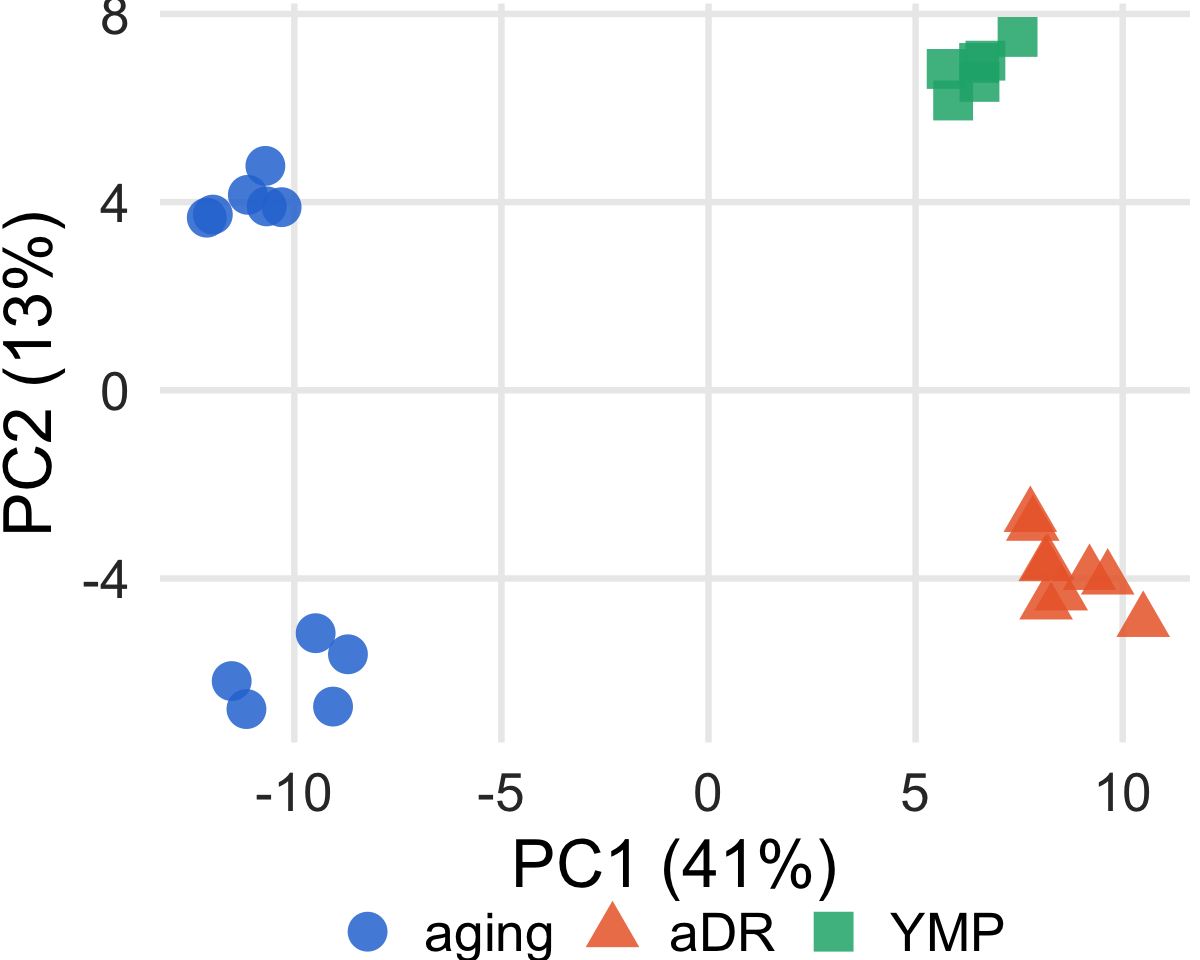

In [6]:
# VST of all 26 samples, then PCA (top 500 genes); colour and shape = cohort
vst_of <- function(srr, min_n = 3) {
  x <- txi; x[c("abundance", "counts", "length")] <- lapply(x[c("abundance", "counts", "length")], \(m) m[, srr])
  d <- suppressMessages(DESeqDataSetFromTximport(x, meta[srr, ], ~ 1))
  suppressMessages(vst(d[rowSums(counts(d) >= 10) >= min_n, ], blind = TRUE))
}
pca_df <- function(v) {
  p <- suppressMessages(plotPCA(v, intgroup = "group", returnData = TRUE, ntop = 500))
  list(d = cbind(p, meta[rownames(p), c("experiment", "sex")]), pv = round(100 * attr(p, "percentVar")))
}
v_all <- vst_of(rownames(meta))
p <- pca_df(v_all)
p$d$experiment <- factor(p$d$experiment, c("aging", "aDR", "YMP"))
p_all <- ggplot(p$d, aes(PC1, PC2, color = experiment, shape = experiment)) + geom_point(size = 10, alpha = 0.85) +
  scale_color_manual(values = COL) + labs(x = paste0("PC1 (", p$pv[1], "%)"), y = paste0("PC2 (", p$pv[2], "%)"),
                                          color = NULL, shape = NULL) + guides(color = guide_legend(override.aes = list(size = 10)))
options(repr.plot.width = 10, repr.plot.height = 8); p_all
save_png(p_all, "pca_all.png", 10, 8)

**Reading the PCA:** PC1 (41 %) separates the aging cohort from the two intervention cohorts, and PC2 (13 %) separates aDR from YMP. The largest differences lie between experiments (separate studies, sequencing runs, sexes and ages), so each comparison is analysed within its own cohort only.

## 3 · Differential expression (DESeq2)
| Choice | Setting (team setup) |
|---|---|
| Input | RSEM expected counts + effective lengths (`DESeqDataSetFromTximport`) |
| Aging | old (18 + 21 months, n = 7) vs young (3 months, n = 4), design `~ sex + age_bin` |
| aDR | aDR (5) vs AL (4), design `~ condition` (all female) |
| YMP | YMP (3) vs PBS (3), design `~ condition` (all male) |
| Gene filter | ≥ 10 reads in at least *n* samples, *n* = smallest group (4, 4, 3) |
| Test | Wald, `results(alpha = 0.05)` |
| DEG | padj < 0.05, no fold-change cutoff |
| Fold changes in plots and comparisons | apeglm-shrunken (`lfcShrink`); p-values are not shrunken |

- **What DESeq2 does:** normalises for depth and gene length, estimates how much each gene varies between replicate mice (sharing information across genes, which matters with 3–5 mice), then tests each gene with a Wald test (log2FC divided by its standard error).
- **Sex term (aging only):** the aging cohort has both sexes (2 males + 2 females per age), and sex differs in brain expression. The term removes these differences, so they do not add noise to the age test. It assumes the age effect is the same in both sexes. The aDR (female) and YMP (male) cohorts are single-sex, so they need no sex term.
- **Shrunken fold changes (apeglm):** pull noisy fold changes of low-count genes towards 0, so plots and comparisons are not dominated by genes with few reads. They change no p-value and no DEG call.
- **Tested genes** (team definition) = genes that pass the gene filter and so get a Wald statistic, fold change and p-value. Some get padj = NA (DESeq2's independent filtering removes genes with too few reads to reach padj < 0.05, or a count outlier); they cannot be DEGs but still enter the GSEA ranking (Section 4).

In [7]:
# Fit one DESeq2 model: samples, design, the tested factor (with the control level first), min_n for the filter
fit_de <- function(srr, design, factor, levels, min_n) {
  cd <- meta[srr, ]; cd[[factor]] <- factor(cd[[factor]], levels = levels)
  x <- txi; x[c("abundance", "counts", "length")] <- lapply(x[c("abundance", "counts", "length")], \(m) m[, srr])
  d <- suppressMessages(DESeqDataSetFromTximport(x, cd, design))
  d <- d[rowSums(counts(d) >= 10) >= min_n, ]
  DESeq(d, quiet = TRUE)
}
# Results table for the tested factor: Wald test (alpha = 0.05) + apeglm-shrunken log2FC + gene symbol, sorted by padj
de_table <- function(dds) {
  coef <- resultsNames(dds)[length(resultsNames(dds))]   # last coefficient = the tested factor
  r <- as.data.frame(results(dds, name = coef, alpha = ALPHA))
  s <- lfcShrink(dds, coef = coef, type = "apeglm", quiet = TRUE)
  tibble(gene_id = rownames(r), symbol = sym[rownames(r)], baseMean = r$baseMean, log2FoldChange = r$log2FoldChange,
         lfc_shrunk = s$log2FoldChange, stat = r$stat, pvalue = r$pvalue, padj = r$padj) %>% arrange(padj)
}

meta$age_bin   <- ifelse(meta$experiment != "aging", NA, ifelse(meta$age_months == 3, "young", "old"))   # aging cohort only
meta$condition <- as.character(meta$group)
srr <- split(rownames(meta), meta$experiment)
dds <- list(
  aging = fit_de(srr$aging, ~ sex + age_bin, "age_bin",   c("young", "old"), min_n = 4),
  aDR   = fit_de(srr$aDR,   ~ condition,     "condition", c("AL", "aDR"),    min_n = 4),
  YMP   = fit_de(srr$YMP,   ~ condition,     "condition", c("PBS", "YMP"),   min_n = 3))
res <- lapply(dds, de_table)
sapply(dds, \(d) tail(resultsNames(d), 1))   # tested coefficient per comparison

                 aging                    aDR                    YMP 
"age_bin_old_vs_young"  "condition_aDR_vs_AL" "condition_YMP_vs_PBS" 

In [8]:
# DEG summary. reference = counts from the team's reference run (results/common), to check that the setup is reproduced
deg_summary <- imap_dfr(res, \(r, n) tibble(comparison = n, tested = sum(!is.na(r$stat)), with_padj = sum(!is.na(r$padj)),
  DEGs = sum(r$padj < ALPHA, na.rm = TRUE), up = sum(r$padj < ALPHA & r$log2FoldChange > 0, na.rm = TRUE),
  down = sum(r$padj < ALPHA & r$log2FoldChange < 0, na.rm = TRUE))) %>%
  mutate(reference = c(175, 118, 50))
deg_summary

  comparison tested with_padj DEGs up  down reference
1 aging      16345  16344     175  138 37   175      
2 aDR        17355  12967     118   46 72   118      
3 YMP        17619  17617      50   22 28    50      

                      comparison symbol  lfc_shrunk padj   
ENSMUSG00000090546.3  aDR        Cdr1    12.2       4.2e-10
ENSMUSG00000083365.2  YMP        Gm12895  7.5       2.3e-04
ENSMUSG00000010122.16 YMP        Slc47a1 -6.1       4.6e-04

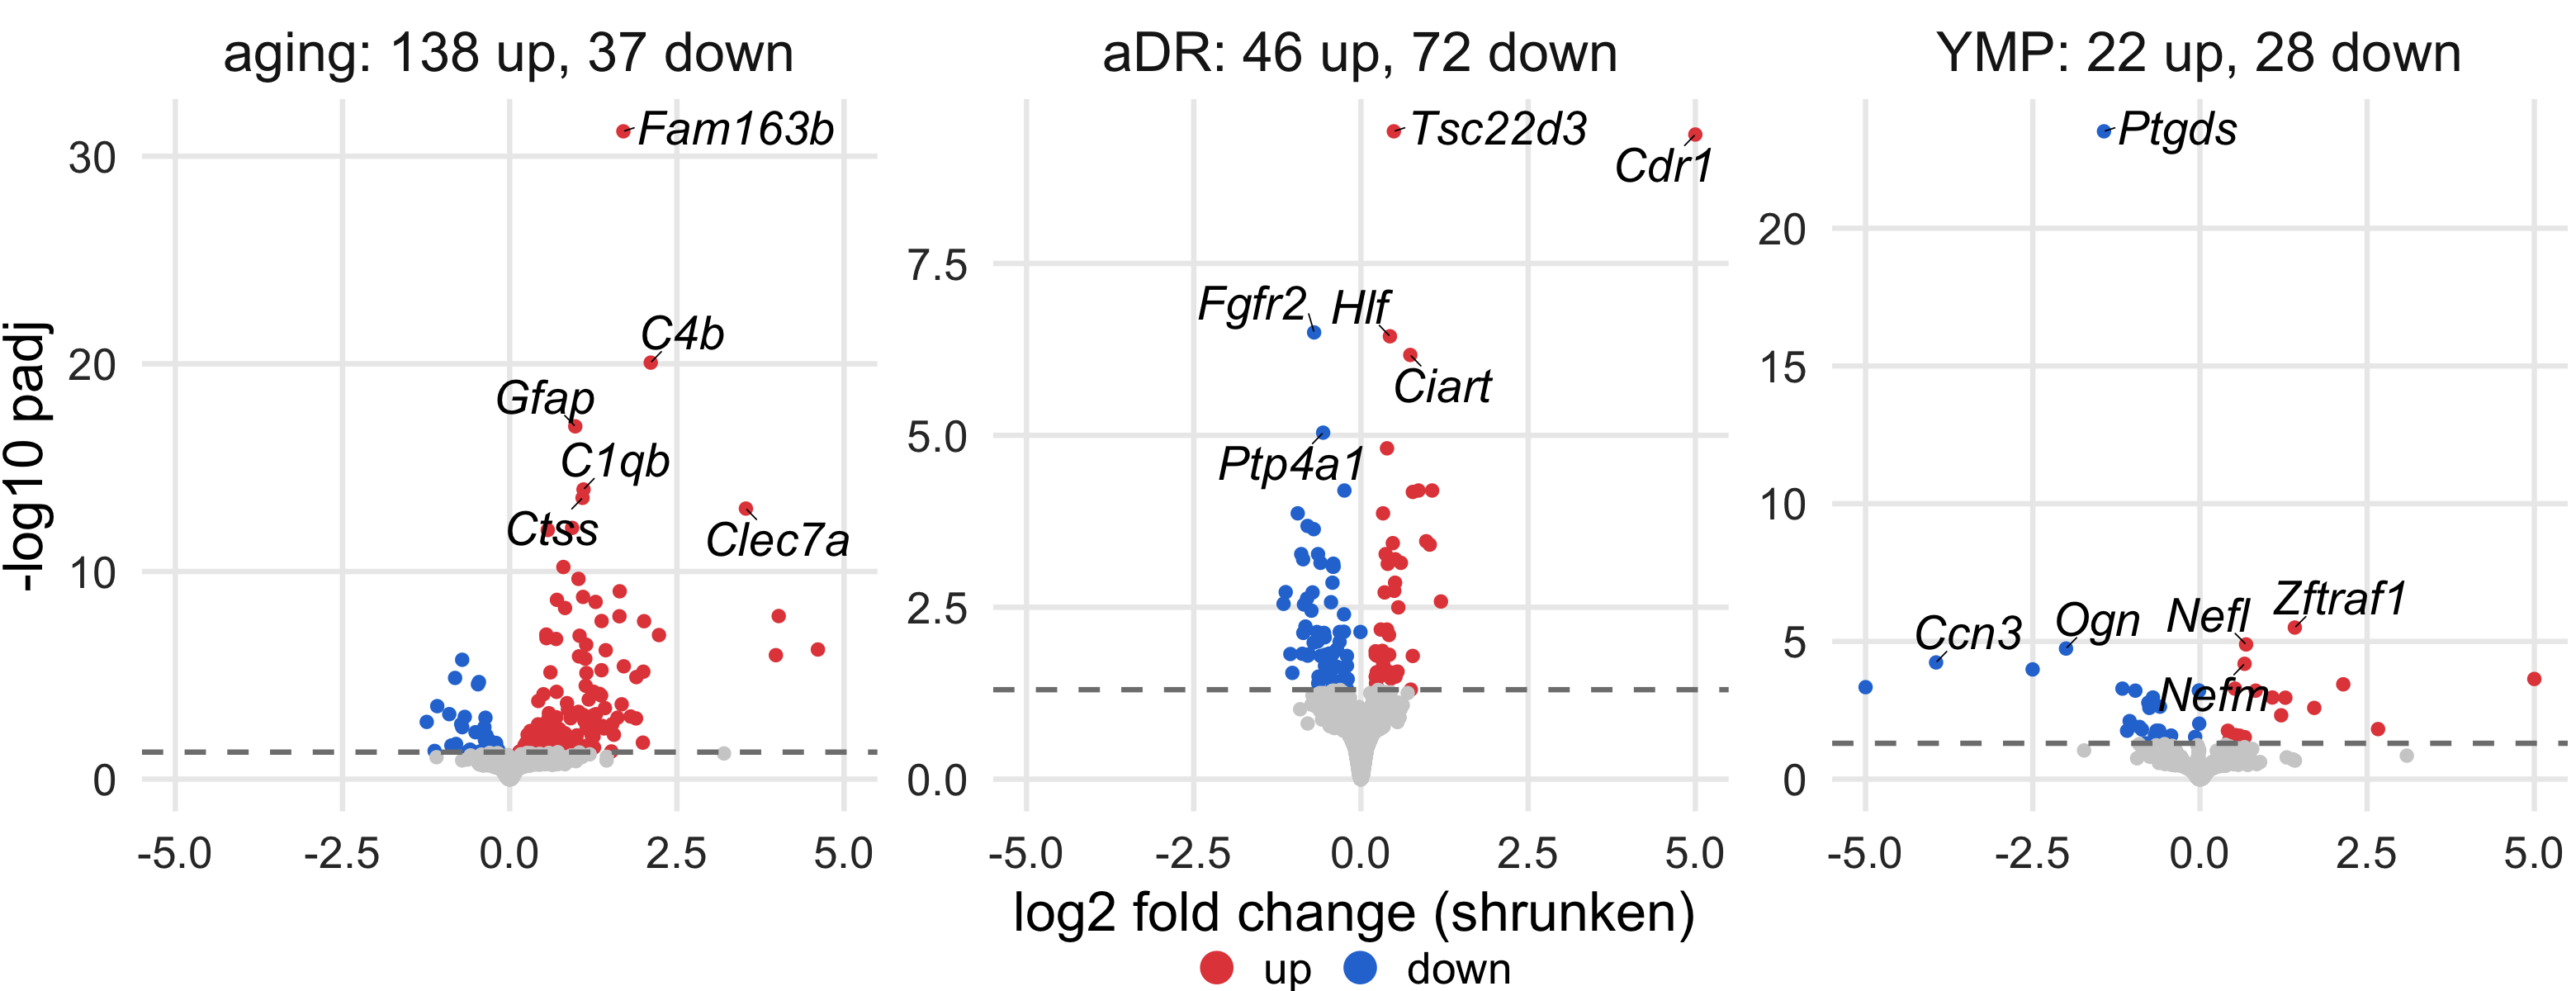

In [9]:
# Volcano plots: x = shrunken log2FC, colour = DEG (padj < 0.05) up / down; the 6 most significant DEGs are named.
# x axis limited to -5..5: the few genes beyond are drawn at the edge (listed below the plot)
vd <- bind_rows(res, .id = "comparison") %>% filter(!is.na(padj)) %>%   # genes with padj only (y axis)
  mutate(comparison = factor(comparison, names(res)),
         call = case_when(padj < ALPHA & log2FoldChange > 0 ~ "up", padj < ALPHA ~ "down", TRUE ~ "ns"),
         title = paste0(comparison, ": ", ave(call == "up", comparison, FUN = sum), " up, ", ave(call == "down", comparison, FUN = sum), " down"),
         title = fct_reorder(title, as.integer(comparison)))
top <- vd %>% filter(call != "ns") %>% group_by(comparison) %>% slice_min(padj, n = 6, with_ties = FALSE)
p_volc <- ggplot(vd, aes(lfc_shrunk, -log10(padj), color = call)) + geom_point(size = 2.5) +
  geom_hline(yintercept = -log10(ALPHA), linetype = "dashed", color = "grey50") +
  geom_text_repel(data = top, aes(label = symbol), color = "black", size = LAB, fontface = "italic", seed = 42, max.overlaps = 30,
                  box.padding = 0.6, min.segment.length = 0) +
  scale_color_manual(values = COL, breaks = c("up", "down"), labels = c("up", "down")) +
  scale_x_continuous(limits = c(-5, 5), oob = scales::squish) +
  facet_wrap(~ title, scales = "free_y") + labs(x = "log2 fold change (shrunken)", y = "-log10 padj", color = NULL) +
  guides(color = guide_legend(override.aes = list(size = 9)))
options(repr.plot.width = 26, repr.plot.height = 10); p_volc
save_png(p_volc, "volcano.png", 26, 10)
vd %>% filter(call != "ns", abs(lfc_shrunk) > 5) %>% transmute(comparison, symbol, lfc_shrunk = round(lfc_shrunk, 1), padj = signif(padj, 2))

In [10]:
# Top 10 DEGs per comparison (shrunken log2FC; positive = higher in old / treated mice)
bind_rows(res, .id = "comparison") %>% filter(padj < ALPHA) %>% group_by(comparison) %>%
  slice_min(padj, n = 10, with_ties = FALSE) %>%
  summarise(top10 = paste0(symbol, " (", sprintf("%+.1f", lfc_shrunk), ")", collapse = ", ")) %>%
  mutate(comparison = factor(comparison, names(res))) %>% arrange(comparison)

  comparison
1 aging     
2 aDR       
3 YMP       
  top10                                                                                                                                            
1 Fam163b (+1.7), C4b (+2.1), Gfap (+1.0), C1qb (+1.1), Ctss (+1.1), Clec7a (+3.5), H2-K1 (+0.9), Ctsd (+0.6), Pcdhga8 (+0.8), C1qc (+1.0)         
2 Tsc22d3 (+0.5), Cdr1 (+12.2), Fgfr2 (-0.7), Hlf (+0.4), Ciart (+0.7), Ptp4a1 (-0.6), Rfxap (+0.4), Nr4a2 (+0.9), Nr4a3 (+1.1), Ado (-0.2)        
3 Ptgds (-1.4), Zftraf1 (+1.4), Nefl (+0.7), Ogn (-2.0), Ccn3 (-3.9), Nefm (+0.7), A730009L09Rik (-2.5), Gm12895 (+7.5), Ttn (+2.1), Slc47a1 (-6.1)

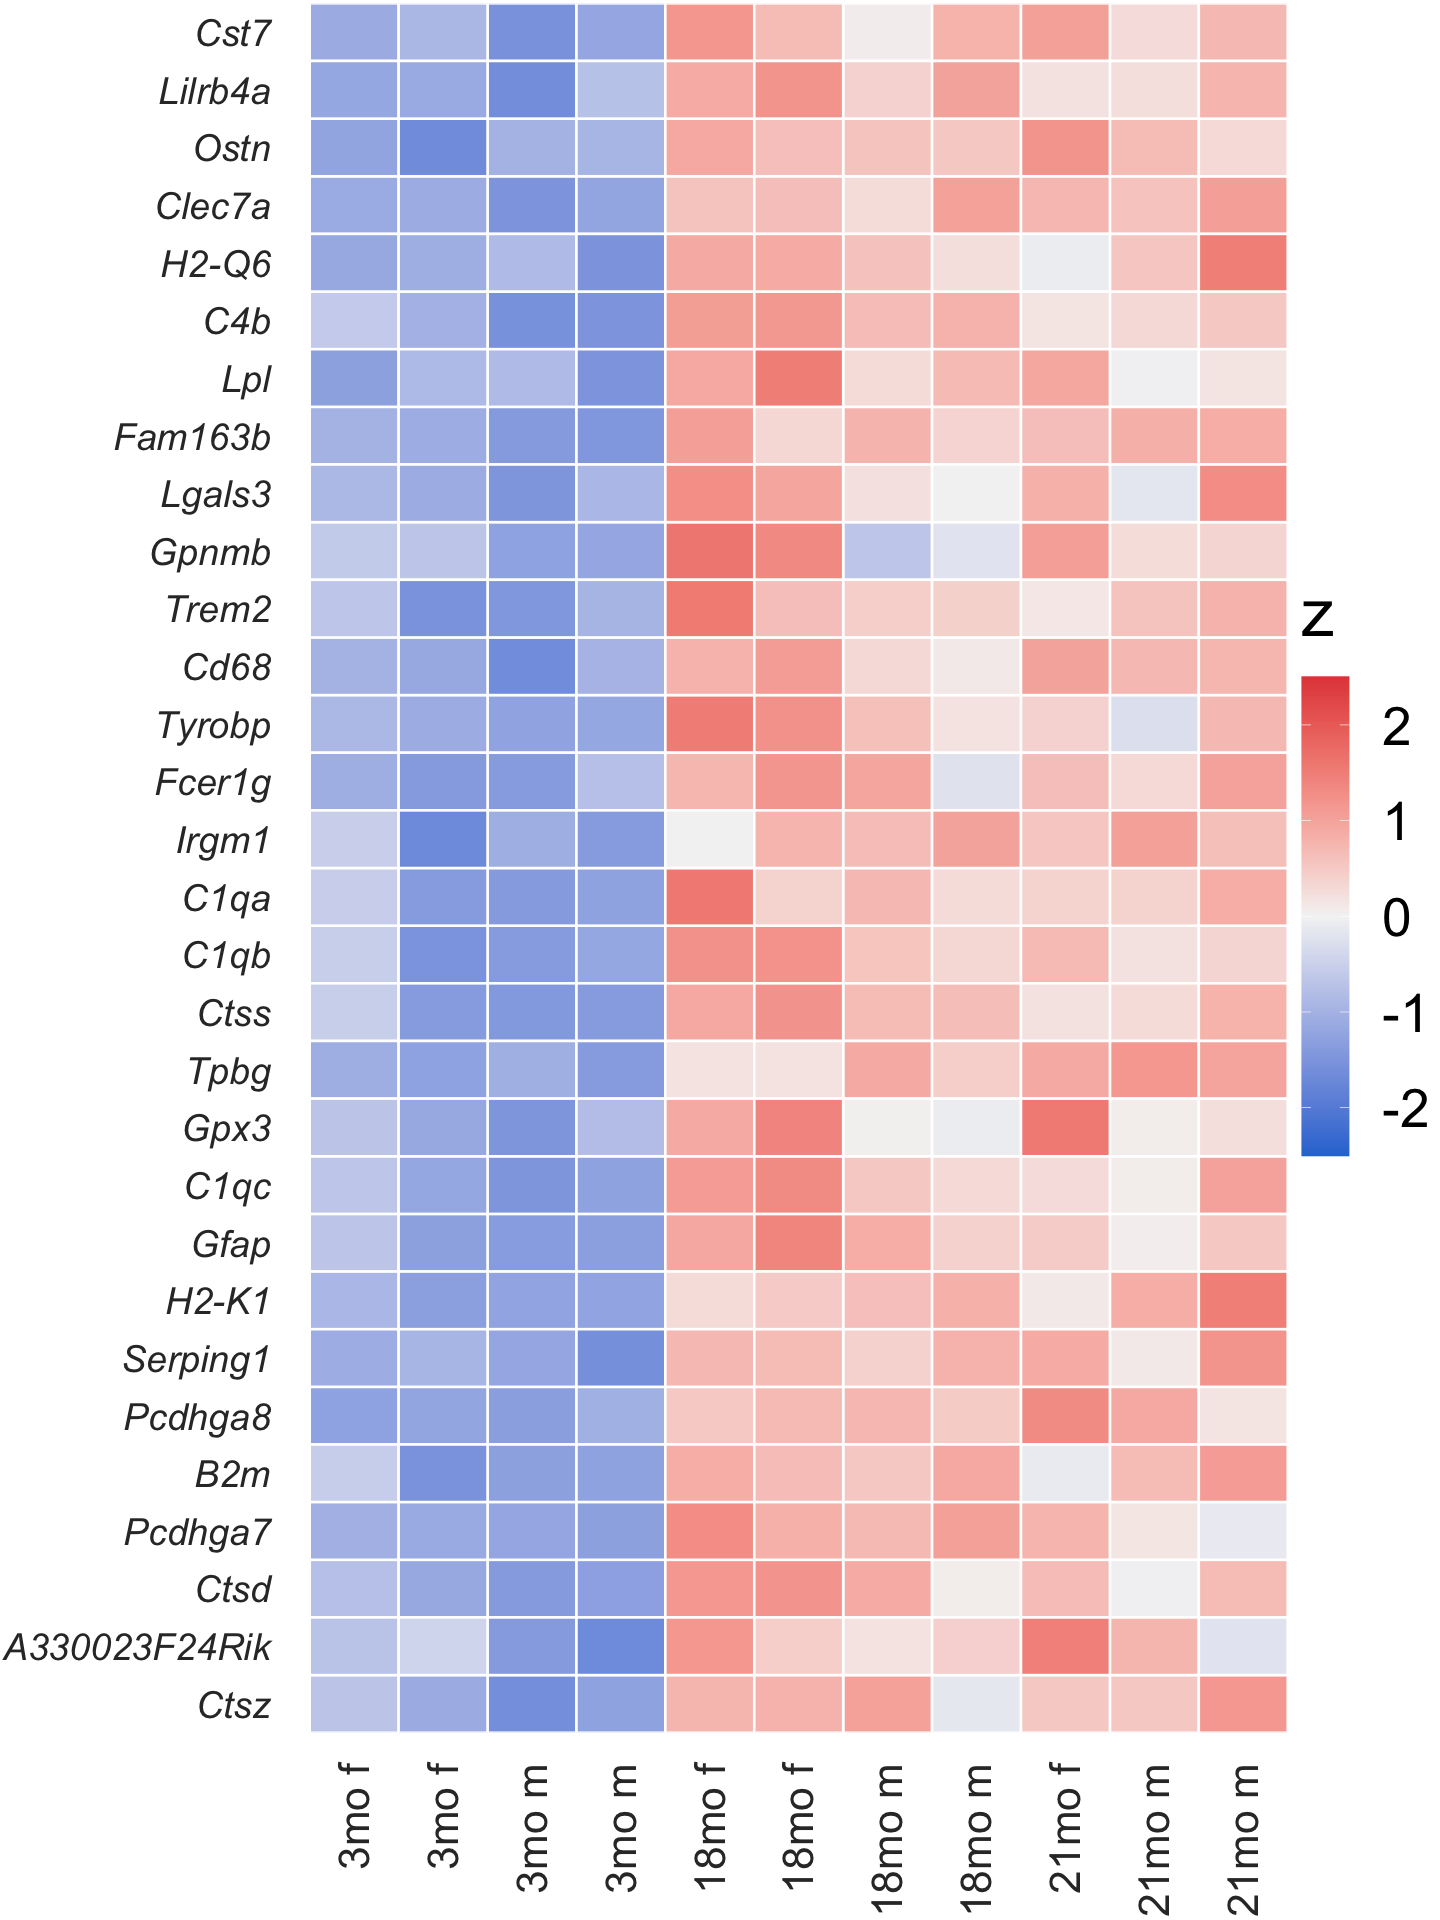

In [11]:
# Heatmap of the 30 most significant aging DEGs (one row per gene, one column per mouse): VST of the aging samples, z-score per gene; columns = mice by age and sex
v_age <- vst_of(srr$aging, min_n = 4)
top_age <- res$aging %>% filter(padj < ALPHA) %>% slice_min(padj, n = 30, with_ties = FALSE)
z <- t(scale(t(assay(v_age)[top_age$gene_id, ])))
ord_s <- rownames(meta[srr$aging, ] %>% arrange(age_months, sex))
ord_g <- top_age$gene_id[order(top_age$log2FoldChange)]
hd <- as.data.frame(as.table(z)) %>% setNames(c("gene_id", "SRR", "z")) %>%
  mutate(gene = factor(sym[as.character(gene_id)], unique(sym[ord_g])),
         mouse = factor(paste0(meta[as.character(SRR), "age_months"], "mo ", substr(meta[as.character(SRR), "sex"], 1, 1)),
                        levels = unique(paste0(meta[ord_s, "age_months"], "mo ", substr(meta[ord_s, "sex"], 1, 1)))),
         SRR = factor(SRR, ord_s), z = pmax(pmin(z, 2.5), -2.5))
p_heat <- ggplot(hd, aes(SRR, gene, fill = z)) + geom_tile(color = "white") +
  scale_fill_gradient2(low = COL[["down"]], mid = "#f4f4f4", high = COL[["up"]], limits = c(-2.5, 2.5)) +
  scale_x_discrete(labels = setNames(as.character(hd$mouse), hd$SRR)) +
  scale_y_discrete(expand = c(0, 0)) + labs(x = NULL, y = NULL, fill = "z") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size = rel(0.8)), axis.text.y = element_text(face = "italic", size = rel(0.7)),
        panel.grid = element_blank(), legend.position = "right", legend.key.height = unit(4, "lines"))
options(repr.plot.width = 12, repr.plot.height = 16); p_heat
save_png(p_heat, "heatmap_aging.png", 12, 16)

In [12]:
# Save the three DE tables (all tested genes; padj NA = removed by independent filtering or a count outlier)
iwalk(res, \(r, n) write_csv(r, file.path(OUT, paste0("de_", n, ".csv"))))
write_csv(deg_summary, file.path(OUT, "deg_summary.csv"))

**Reading the differential expression**
- **Reproducibility check:** DEG counts equal the team reference (aging 175, aDR 118, YMP 50).
- **Tested vs with padj:** for aDR, 4,388 of the 17,355 tested genes get padj = NA from independent filtering (low-count genes that could not reach padj < 0.05). They are still in the GSEA ranking.
- **Volcano plots:** each point is a gene; right = higher in old / treated mice; higher = more significant; dashed line = padj 0.05. Genes beyond ±5 are drawn at the edge (listed below the plot).
- **Aging (138 up, 37 down):** the top genes form a neuroinflammation signature: complement (*C4b, C1qa, C1qb, C1qc*), activated microglia (*Clec7a, Cst7, Trem2, Tyrobp, Cd68, Lgals3, Gpnmb*), MHC class I (*H2-K1, H2-Q6, B2m*), lysosomal cathepsins (*Ctss, Ctsd, Ctsz*) and the astrocyte gene *Gfap*.
- **Heatmap:** colour = z-score, i.e. a mouse's value relative to that gene's average over the 11 aging mice (red = above, blue = below). The 4 young mice are below average for all 30 genes; the 18- and 21-month mice look alike, consistent with pooling them.
- **aDR (46 up, 72 down):** mostly small fold changes. Top genes include glucocorticoid- and circadian-responsive genes (*Tsc22d3, Hlf, Ciart*) and immediate early genes (*Nr4a2, Nr4a3*), not the aging inflammation genes. *Cdr1* (log2FC +12) has 0 reads in all 4 AL mice and 15–555 in the aDR mice (it is also detected in some PBS / YMP mice): an on/off pattern to interpret with caution.
- **YMP (22 up, 28 down):** few genes; several large fold changes rest on 3 vs 3 mice (*Ccn3, Slc47a1, Gm12895*). The most significant gene, *Ptgds*, and *Ogn* and *Slc47a1* are typical of the meninges, so part of this signal may reflect how much meninges was included in each dissection rather than a plasma effect.

## 4 · Pathways: Hallmark GSEA
- **What:** for each of the 50 Hallmark gene sets (curated groups of genes for one biological process, e.g. *interferon alpha response*), test whether its genes sit mostly at the top or the bottom of a ranked gene list.
- **Why:** many genes changing a little in the same direction can be biologically meaningful even when few are DEGs individually.
- **How:** all tested genes ranked by the Wald statistic (one value per gene symbol; for duplicated symbols the strongest is kept); `fgsea` on mouse-native MSigDB Hallmark sets (`db_species = "MM"`), sets of 15–500 genes, seed 42 (fgsea uses random permutations).
- **How to read:** **NES** (normalised enrichment score) > 0 = the set is higher in old / treated mice, < 0 = lower; significant = padj < 0.05 (Benjamini–Hochberg over the 50 sets).

In [13]:
# Hallmark GSEA for each comparison
hallmark <- msigdbr(species = "Mus musculus", db_species = "MM", collection = "MH")
hallmark <- split(hallmark$gene_symbol, hallmark$gs_name)
cat("msigdbr", as.character(packageVersion("msigdbr")), "|", length(hallmark), "Hallmark sets\n")
run_gsea <- function(r) {
  r <- r %>% filter(!is.na(stat), !is.na(symbol), symbol != "") %>% group_by(symbol) %>%
    slice_max(abs(stat), n = 1, with_ties = FALSE) %>% ungroup()
  set.seed(42)
  suppressWarnings(fgsea(hallmark, setNames(r$stat, r$symbol), minSize = 15, maxSize = 500)) %>%
    as_tibble() %>% select(pathway, NES, pval, padj, size) %>% arrange(padj)
}
gsea <- bind_rows(lapply(res, run_gsea), .id = "comparison")
write_csv(gsea, file.path(OUT, "gsea_hallmark.csv"))
gsea %>% group_by(comparison = factor(comparison, names(res))) %>%
  summarise(significant = sum(padj < ALPHA), up = sum(padj < ALPHA & NES > 0), down = sum(padj < ALPHA & NES < 0))

msigdbr 26.1.1 | 50 Hallmark sets


  comparison significant up down
1 aging      15           7  8  
2 aDR        16           6 10  
3 YMP        24          22  2  

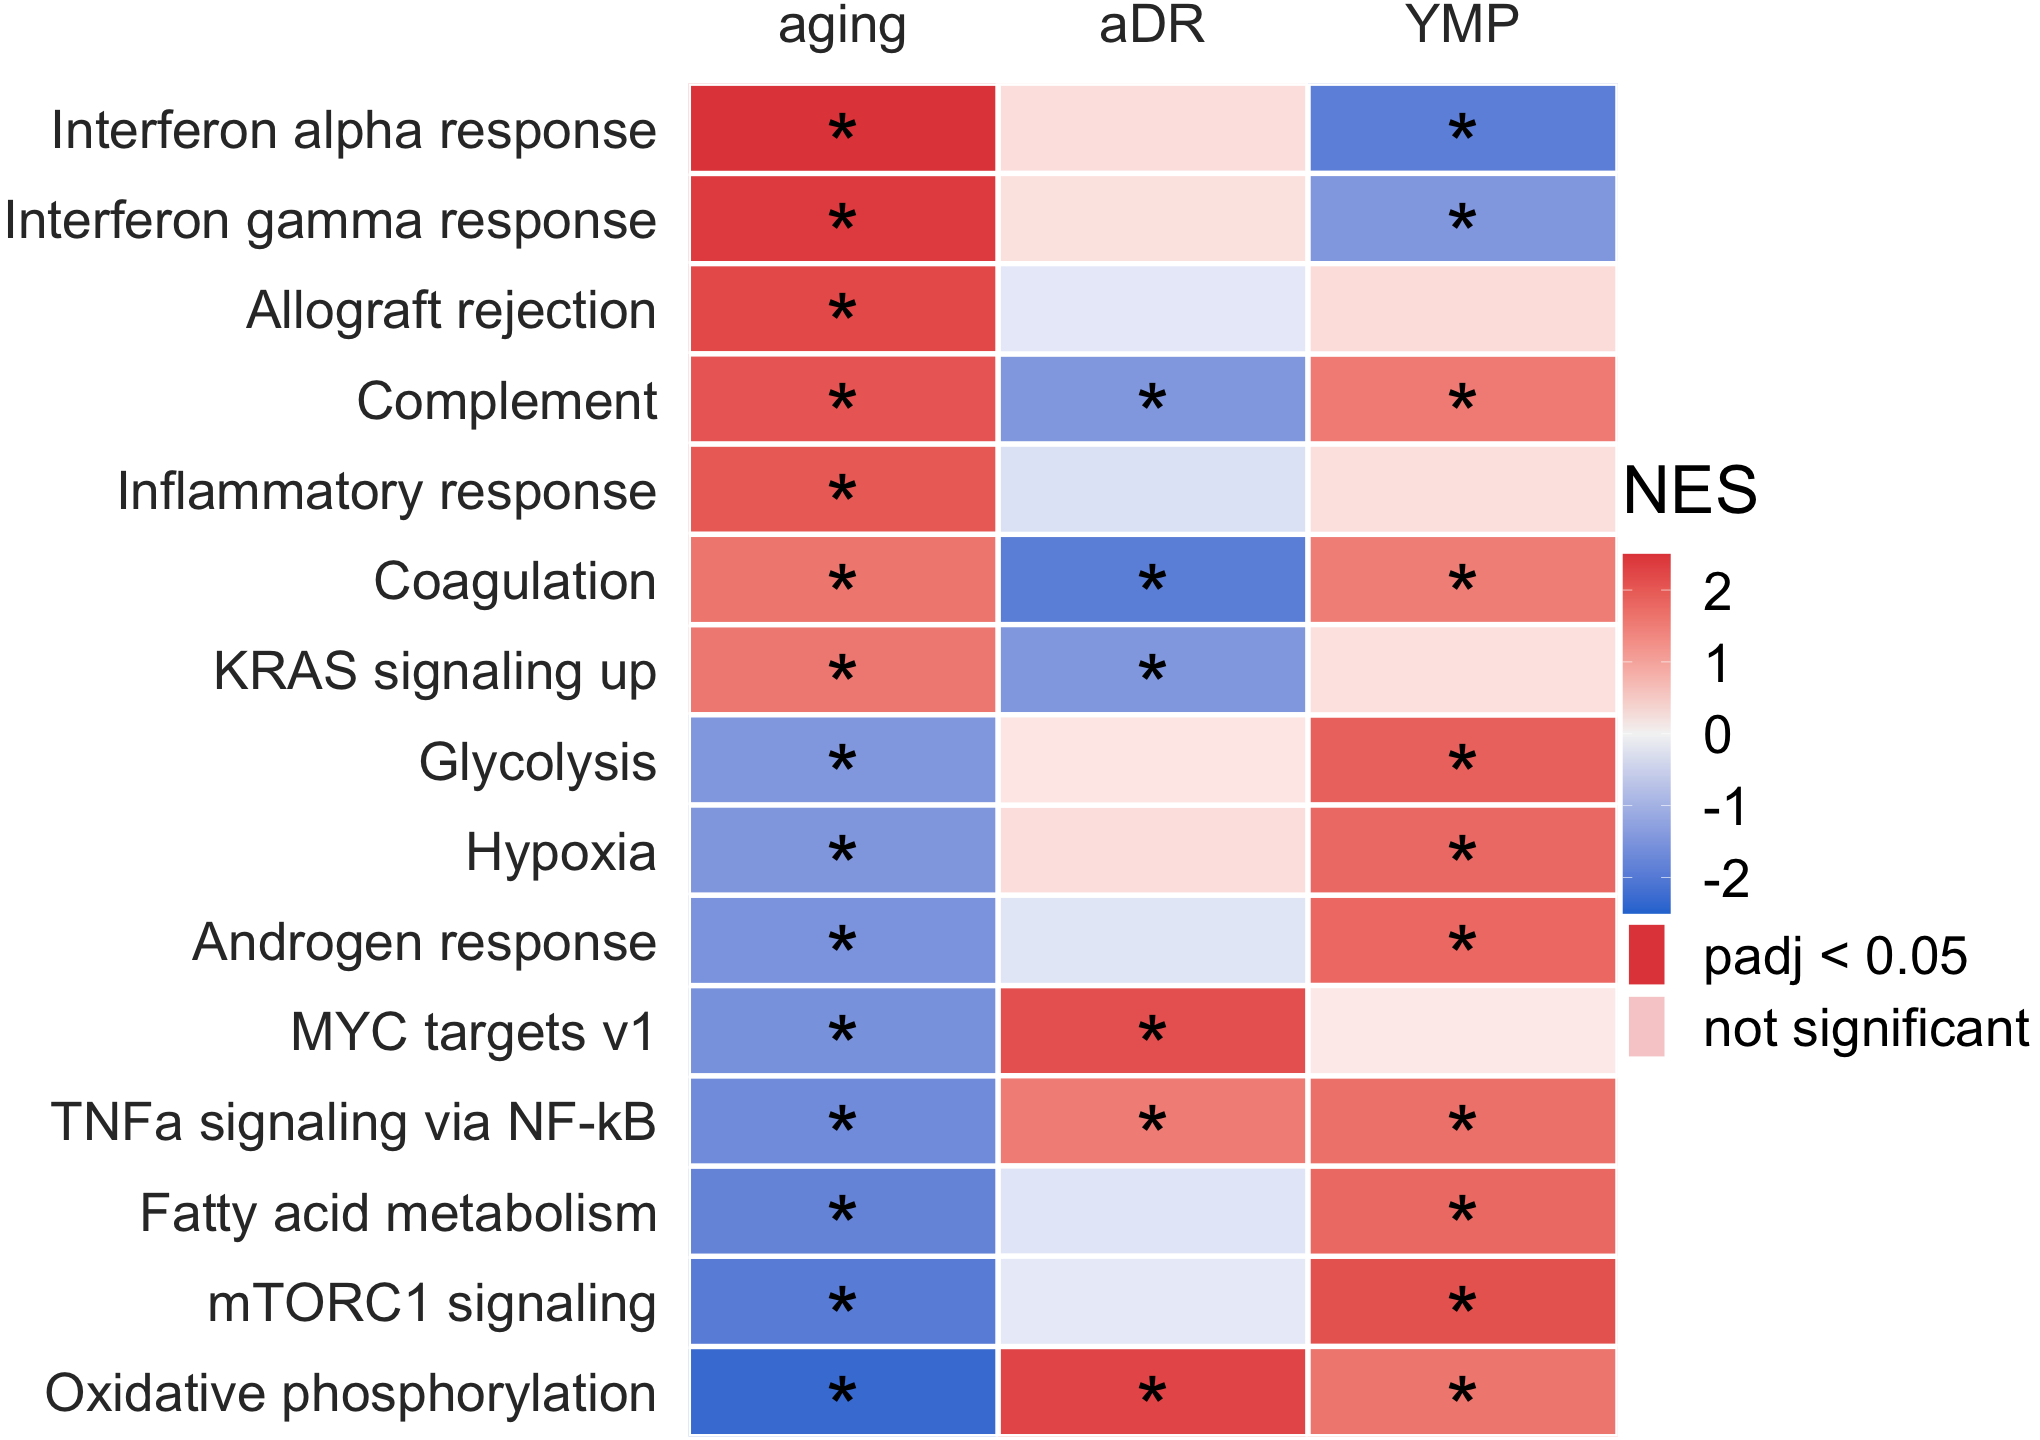

In [14]:
# One figure: the 15 Hallmark sets significant in aging (rows, ordered by aging NES), with their NES in aging, aDR and YMP.
# Colour = NES (red = higher in old / treated mice, blue = lower); solid tile with * = padj < 0.05; faded tile = not significant
nice <- \(p) str_to_sentence(gsub("_", " ", sub("^HALLMARK_", "", p))) %>%
  str_replace_all(c("^Tnfa signaling via nfkb" = "TNFa signaling via NF-kB", "^Il6 jak stat3" = "IL6-JAK-STAT3", "^Il2 stat5" = "IL2-STAT5",
                    "^Mtorc1" = "mTORC1", "^Myc" = "MYC", "^E2f" = "E2F", "^G2m" = "G2M", "^Kras" = "KRAS", "^P53" = "p53", "^Uv" = "UV",
                    "^Tgf beta" = "TGF-beta", "^Pi3k akt mtor" = "PI3K-AKT-mTOR", "^Dna" = "DNA", "^Wnt beta catenin" = "WNT-beta-catenin"))
ord <- gsea %>% filter(comparison == "aging", padj < ALPHA) %>% arrange(NES) %>% pull(pathway)
gd <- gsea %>% filter(pathway %in% ord) %>%
  mutate(set = factor(nice(pathway), nice(ord)), comparison = factor(comparison, names(res)),
         sig = factor(ifelse(padj < ALPHA, "padj < 0.05", "not significant"), c("padj < 0.05", "not significant")))
lim <- max(abs(gd$NES))
p_gsea <- ggplot(gd, aes(comparison, set, fill = NES, alpha = sig)) + geom_tile(color = "white", linewidth = 1.5) +
  geom_text(aes(label = ifelse(padj < ALPHA, "*", "")), size = 18, vjust = 0.75, alpha = 1) +
  scale_fill_gradient2(low = COL[["down"]], mid = "#f4f4f4", high = COL[["up"]], limits = c(-lim, lim)) +
  scale_alpha_manual(values = c("padj < 0.05" = 1, "not significant" = 0.3), name = NULL) +
  scale_x_discrete(position = "top", expand = c(0, 0)) + scale_y_discrete(expand = c(0, 0)) + labs(x = NULL, y = NULL) +
  theme(panel.grid = element_blank(), legend.position = "right", legend.key.height = unit(3, "lines")) +
  guides(alpha = guide_legend(override.aes = list(fill = COL[["up"]])), fill = guide_colorbar(order = 1))
options(repr.plot.width = 17, repr.plot.height = 12); p_gsea
save_png(p_gsea, "gsea_hallmark.png", 17, 12)

In [15]:
# Descriptive count: of the 15 aging sets, how many are also significant in each intervention, in the opposite or the same direction
aging_sets <- gsea %>% filter(comparison == "aging", padj < ALPHA) %>% select(pathway, NES_aging = NES)
gsea %>% filter(comparison != "aging", padj < ALPHA) %>% inner_join(aging_sets, by = "pathway") %>%
  group_by(intervention = comparison) %>%
  summarise(aging_sets = nrow(aging_sets), significant_in_both = n(),
            opposite = sum(sign(NES) != sign(NES_aging)), same = sum(sign(NES) == sign(NES_aging)),
            opposite_sets = paste(nice(pathway[sign(NES) != sign(NES_aging)]), collapse = ", "),
            same_sets = paste(nice(pathway[sign(NES) == sign(NES_aging)]), collapse = ", ")) %>%
  arrange(match(intervention, c("aDR", "YMP")))

  intervention aging_sets significant_in_both opposite same
1 aDR          15          6                  6        0   
2 YMP          15         11                  9        2   
  opposite_sets                                                                                                                                                                             
1 Oxidative phosphorylation, MYC targets v1, Coagulation, TNFa signaling via NF-kB, KRAS signaling up, Complement                                                                           
2 mTORC1 signaling, Glycolysis, Hypoxia, Interferon alpha response, Fatty acid metabolism, TNFa signaling via NF-kB, Androgen response, Oxidative phosphorylation, Interferon gamma response
  same_sets              
1                        
2 Complement, Coagulation

**Reading the pathways**
- **Figure:** rows = the 15 Hallmark sets significant in aging, ordered by the aging NES; columns = their NES in aging, aDR and YMP. Red = higher in old / treated mice, blue = lower. Solid tile with * = padj < 0.05; faded tile = not significant. Sets significant only in an intervention are in `output/gsea_hallmark.csv` (all 50 sets × 3 comparisons).
- **Aging (15 sets):** up: interferon α and γ responses, allograft rejection, complement, inflammatory response, coagulation, KRAS signalling; down: oxidative phosphorylation, mTORC1, fatty acid metabolism, MYC targets, TNFα/NF-κB, glycolysis, hypoxia, androgen response.
- **aDR (16 sets):** all 6 aging sets that are also significant in aDR move in the opposite direction (complement, coagulation and KRAS down; oxidative phosphorylation, MYC targets and TNFα/NF-κB up).
- **YMP (24 sets, 22 up):** 9 of the 11 shared sets move opposite to aging (interferon responses down; several metabolic sets up), 2 in the same direction (complement, coagulation). Because almost all YMP sets go up, its 'opposite' calls are mostly the sets that go down with age: partly a general upward shift, not a specific reversal.
- **Caution:** gene sets share genes, so these counts are not independent pieces of evidence, and the counting table is descriptive (no test).

## 5 · Aging vs interventions
- **What:** do the genes that change with age change in the opposite direction after aDR or YMP?
- **How:**
  1. Aging genes = the 175 aging DEGs (padj < 0.05).
  2. Keep those with a shrunken fold change in the intervention model.
  3. Plot aging log2FC (x) against intervention log2FC (y), one panel per intervention. Upper-left and lower-right quadrants = **opposite** to aging.
  4. Describe with **Spearman ρ** (rank correlation; negative = opposite to aging overall, 0 = unrelated), **% opposite sign**, and the **median |log2FC|** (how large the intervention changes are). Genes that are also intervention DEGs are highlighted.
- **Why only fold changes:** the cohorts are separate experiments (different sequencing runs, sexes and ages), so expression values cannot be compared directly; fold changes within each cohort can.
- **No significance test:** aging genes are correlated with each other, not independent, so a p-value for the % opposite (e.g. a binomial test against 50 %) would overstate the evidence. With fold changes near 0, the sign is close to random, so the % opposite must be read together with the median |log2FC|.

In [16]:
# Compare each intervention with aging over the aging DEGs
aging_deg <- res$aging %>% filter(padj < ALPHA) %>% select(gene_id, symbol, aging = lfc_shrunk)
cmp <- bind_rows(lapply(c("aDR", "YMP"), \(n) aging_deg %>%
  inner_join(res[[n]] %>% select(gene_id, lfc_int = lfc_shrunk, padj_int = padj), by = "gene_id") %>%
  filter(!is.na(lfc_int)) %>%
  mutate(panel = n, opposite = sign(aging) != sign(lfc_int), both_DEG = !is.na(padj_int) & padj_int < ALPHA)))
vs_aging <- cmp %>% group_by(intervention = panel) %>%
  summarise(aging_DEGs = nrow(aging_deg), compared = n(), spearman_rho = round(cor(aging, lfc_int, method = "spearman"), 2),
            pct_opposite = round(100 * mean(opposite), 1),
            median_abs_lfc_aging = round(median(abs(aging)), 2), median_abs_lfc_int = round(median(abs(lfc_int)), 2), DEG_in_both = sum(both_DEG),
            both_opposite = sum(both_DEG & opposite), both_same = sum(both_DEG & !opposite)) %>%
  arrange(match(intervention, c("aDR", "YMP")))
write_csv(vs_aging, file.path(OUT, "intervention_vs_aging.csv"))
vs_aging

  intervention aging_DEGs compared spearman_rho pct_opposite median_abs_lfc_aging median_abs_lfc_int DEG_in_both both_opposite both_same
1 aDR          175        175       0.13        50.9         0.7                  0.01               5           0             5        
2 YMP          175        175      -0.09        62.3         0.7                  0.01               2           2             0        

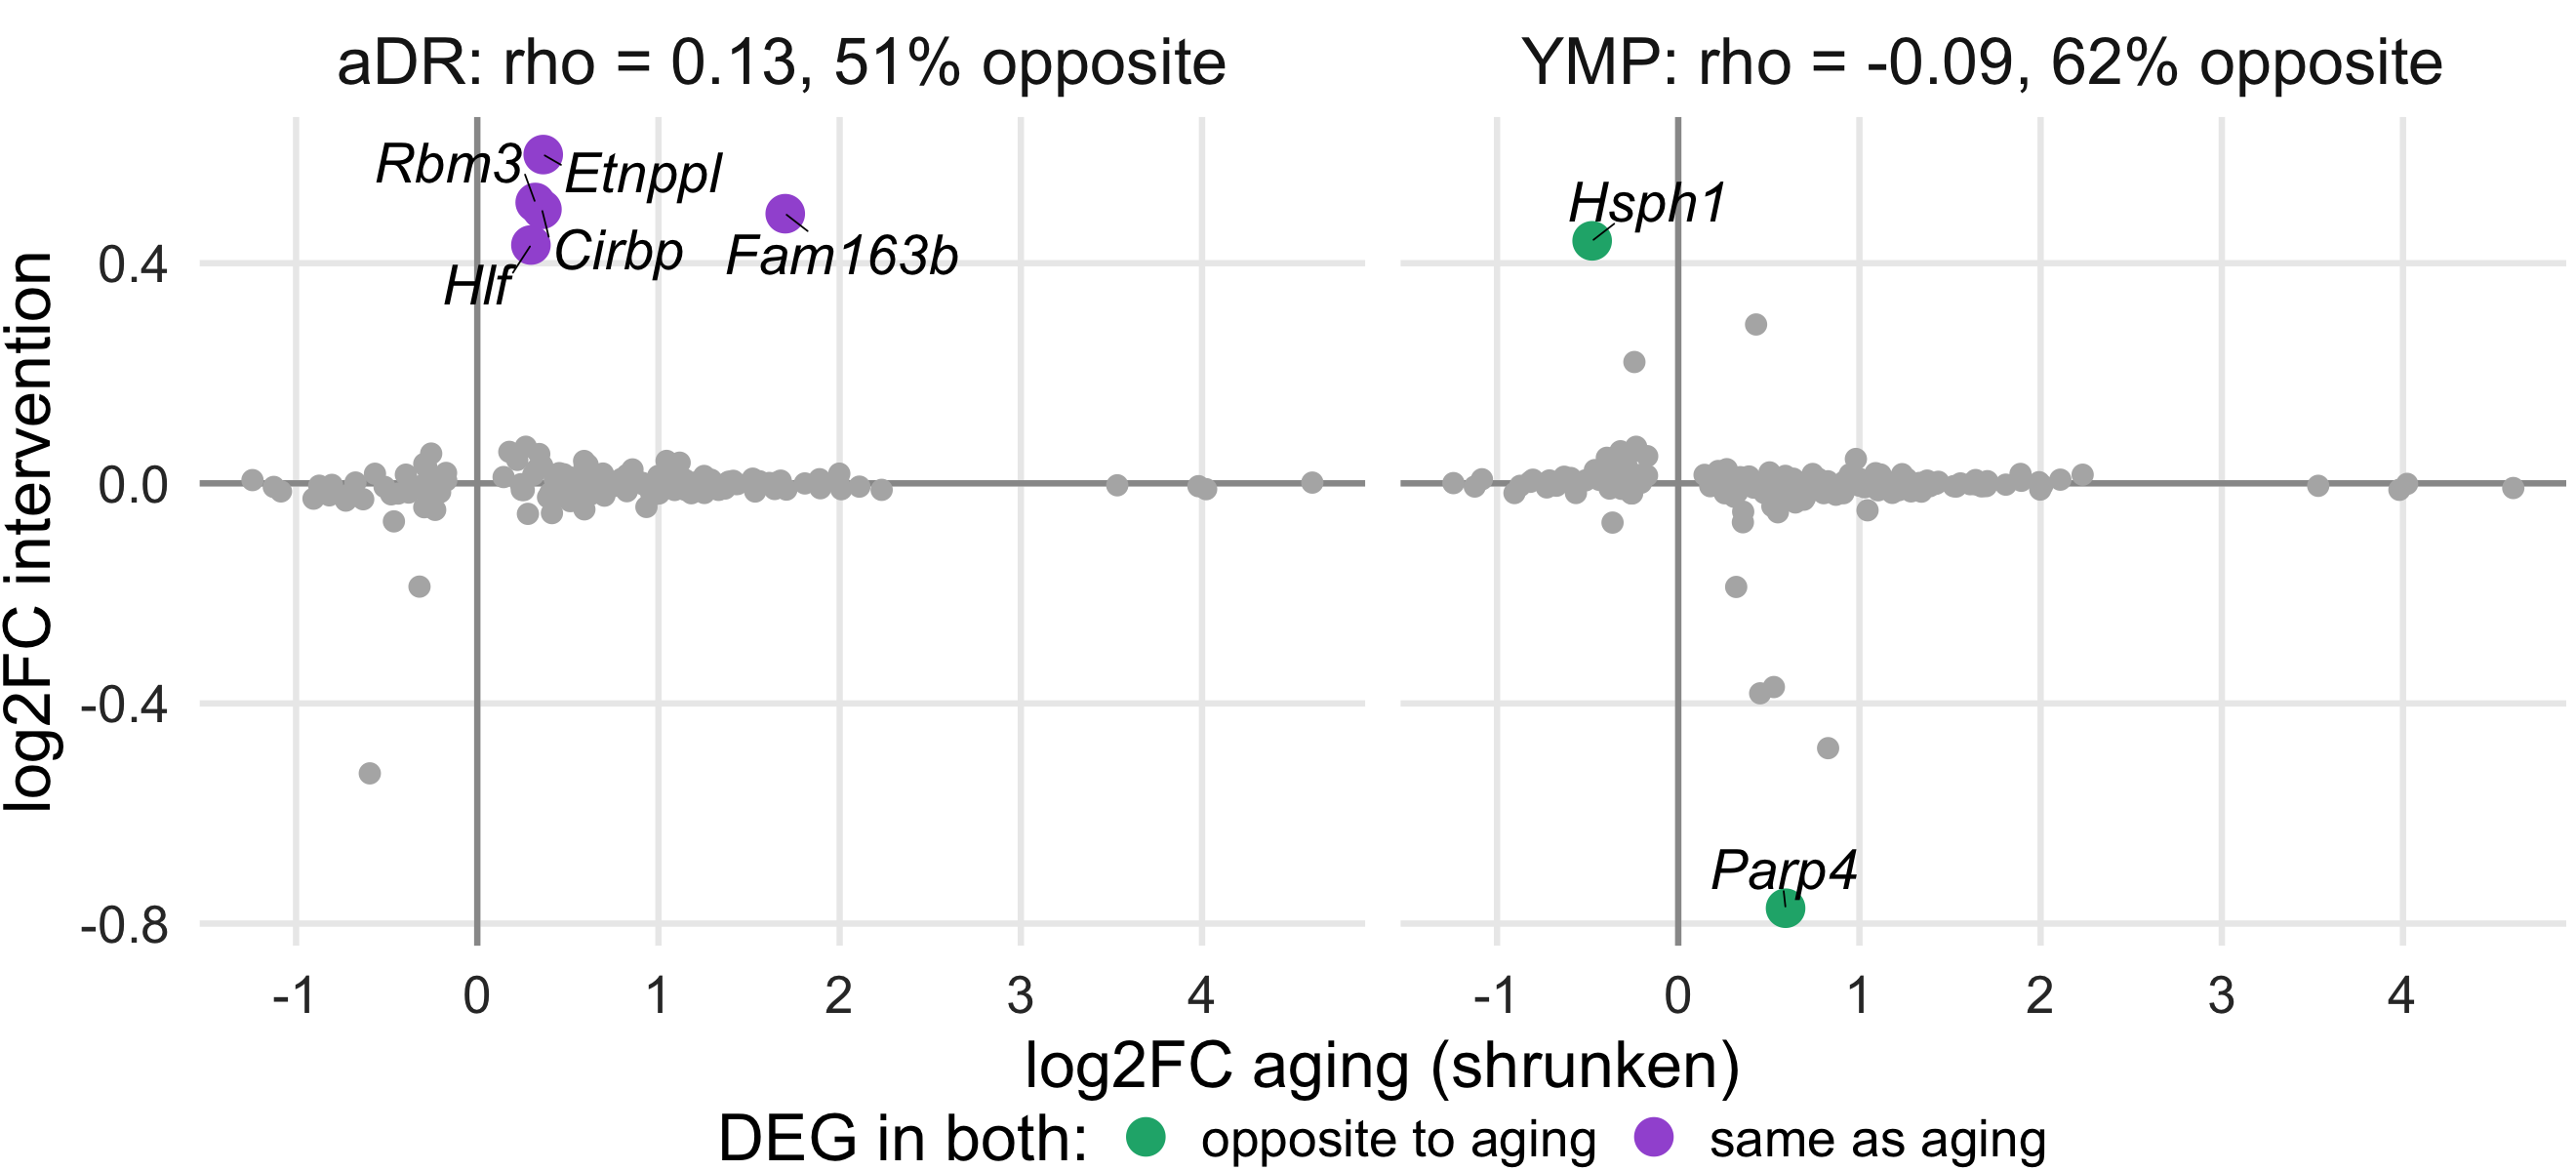

In [17]:
# Scatter per intervention: grey = aging DEG only; coloured and named = DEG in aging and in the intervention
ttl <- with(vs_aging, setNames(sprintf("%s: rho = %.2f, %.0f%% opposite", intervention, spearman_rho, pct_opposite), intervention))
cmp$title <- factor(ttl[cmp$panel], ttl[c("aDR", "YMP")])
p_vs <- ggplot(cmp, aes(aging, lfc_int)) +
  geom_hline(yintercept = 0, color = "grey60") + geom_vline(xintercept = 0, color = "grey60") +
  geom_point(data = filter(cmp, !both_DEG), color = "grey70", size = 4) +
  geom_point(data = filter(cmp, both_DEG), aes(color = ifelse(opposite, "opposite to aging", "same as aging")), size = 9) +
  geom_text_repel(data = filter(cmp, both_DEG), aes(label = symbol), size = LAB, seed = 42, max.overlaps = 50, fontface = "italic",
                  box.padding = 0.8, min.segment.length = 0) +
  scale_color_manual(values = c("opposite to aging" = "#1baf7a", "same as aging" = "#a35bd6")) +
  facet_wrap(~ title) + labs(x = "log2FC aging (shrunken)", y = "log2FC intervention", color = "DEG in both:") +
  guides(color = guide_legend(override.aes = list(size = 9)))
options(repr.plot.width = 22, repr.plot.height = 10); p_vs
save_png(p_vs, "intervention_vs_aging.png", 22, 10)

In [18]:
# Genes that are DEGs in aging and in an intervention
cmp %>% filter(both_DEG) %>% transmute(intervention = panel, symbol, aging = round(aging, 2), intervention_lfc = round(lfc_int, 2),
                                       padj_int = signif(padj_int, 2), direction = ifelse(opposite, "opposite", "same")) %>%
  arrange(intervention, direction, desc(abs(aging)))

                      intervention symbol  aging intervention_lfc padj_int direction
ENSMUSG00000054509.9  YMP          Parp4    0.59 -0.77            1.7e-03  opposite 
ENSMUSG00000029657.17 YMP          Hsph1   -0.48  0.44            4.6e-02  opposite 
ENSMUSG00000009216.9  aDR          Fam163b  1.70  0.49            2.8e-02  same     
ENSMUSG00000019232.16 aDR          Etnppl   0.36  0.60            7.1e-04  same     
ENSMUSG00000045193.15 aDR          Cirbp    0.36  0.50            1.8e-03  same     
ENSMUSG00000031167.18 aDR          Rbm3     0.32  0.51            1.4e-03  same     
ENSMUSG00000003949.18 aDR          Hlf      0.30  0.43            3.6e-07  same     

**Reading the comparison**
- **Size of the changes:** aging DEGs change by a median |log2FC| of 0.70 with age, but by only 0.01 after aDR or YMP (shrunken). For almost all aging genes, neither intervention produces a measurable change. The scatter plots show this as a flat band of points around y = 0.
- **aDR:** ρ = 0.13 and 51 % opposite sign, i.e. no opposition. The 5 genes that are DEGs in both all move in the *same* direction as aging (*Fam163b, Etnppl, Cirbp, Rbm3, Hlf*); *Cirbp* and *Rbm3* are cold-inducible genes, possibly reflecting lower body temperature under dietary restriction.
- **YMP:** ρ = −0.09 and 62 % opposite sign, but with fold changes this close to 0 the signs are largely noise, so this is at most a weak tendency. Only 2 genes are DEGs in both, both opposite to aging (*Parp4, Hsph1*).

**Gene level vs pathway level**

| Level | aDR | YMP |
|---|---|---|
| Individual aging genes (175) | not opposed (ρ = 0.13, 51 % opposite, median change 0.01) | weak tendency at most (ρ = −0.09, 62 % opposite, median change 0.01) |
| Aging genes significant in both | 5, all same direction as aging | 2, both opposite |
| Hallmark pathways (Section 4) | 6 of 6 shared aging sets opposite | 9 of 11 opposite, within a general upward shift |

The two levels answer different questions: pathways summarise small coordinated shifts across many genes (most not aging DEGs), while the gene level asks whether the specific aging genes move back. Opposition at the pathway level does **not** mean the aging genes themselves are reversed.

**Possible confounding**
- The aging signature comes from a different experiment (other mice, sequencing run, and both sexes) than the interventions (aDR female only, YMP male only, all 19 months old). Sex-specific aging changes and batch differences can therefore weaken or distort the comparison.
- Dissection differences (meninges, choroid plexus) change cell-type composition and can mimic or mask expression changes in all three comparisons.

## Summary
**Main findings**
- **Aging** (old vs young): 175 DEGs, mostly up; a neuroinflammation signature (complement, activated microglia, MHC class I, cathepsins, *Gfap*), with interferon and inflammatory pathways up and oxidative phosphorylation, mTORC1 and other metabolic pathways down.
- **aDR:** 118 DEGs with small effects (glucocorticoid, circadian, immediate early genes). Pathways: the 6 aging sets also significant in aDR are all opposite to aging. Genes: the aging genes are essentially unchanged (median |log2FC| 0.01; ρ = 0.13).
- **YMP:** 50 DEGs, partly meningeal genes. Pathways: 9 of 11 shared aging sets opposite to aging, within a general upward shift. Genes: aging genes essentially unchanged (median |log2FC| 0.01; ρ = −0.09).
- **Conclusion:** both interventions shift some aging-related pathways in the opposite direction, but neither reverses the individual aging genes in these data.

**Limitations**
- 3–5 mice per group: modest power; single-gene fold changes from 3 vs 3 mice are uncertain.
- Separate experiments with different sexes and ages: aDR and YMP are each compared with aging only, never with each other; batch and sex-specific effects can distort the comparison.
- Bulk tissue: dissection differences can appear as expression changes.
- A shrunken log2FC near 0 means little evidence of change, not proof of no change.
- The comparison with aging is descriptive; no test of 'rejuvenation' is made.

**Methodological decisions**

| Decision | Reason |
|---|---|
| RSEM counts + effective lengths (tximport workflow) | corrects for depth and per-sample gene length |
| Exclude SRR21355389 | haemoglobin genes 11–15× above any other aging sample (blood contamination) |
| Keep SRR23914572 | choroid plexus genes, not blood (team decision) |
| Pool 18 + 21 months, `~ sex + age_bin` | team decision; the sex term removes sex differences from the age test (both sexes in the aging cohort) |
| Filter ≥ 10 reads in the smallest-group size; Wald test; padj < 0.05, `alpha = 0.05`; no fold-change cutoff | team setup |
| apeglm-shrunken log2FC for plots and comparisons | stable fold changes for low-count genes |
| Hallmark GSEA on the Wald statistic | uses all tested genes, not only DEGs |
| No test of the % opposite | aging genes are not independent |
| Removed from the original notebook | correlation clustering, expression histograms, 21 vs 18 month analysis, aDR / YMP heatmaps, GO BP, camera, permutation and binomial tests, alternative aging signatures, cell-type scores, GO of reversed genes |

In [19]:
# Software versions (reproducibility)
sessionInfo()

R version 4.4.3 (2025-02-28)
Platform: aarch64-apple-darwin20.0.0
Running under: macOS 27.2.1

Matrix products: default
BLAS/LAPACK: /Users/jianzhouyao/Desktop/RNAseq_aging/.pixi/envs/default/lib/libopenblas.0.dylib;  LAPACK version 3.12.0

locale:
[1] C.UTF-8/C.UTF-8/C.UTF-8/C/C.UTF-8/C.UTF-8

time zone: Europe/Zurich
tzcode source: system (macOS)

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] lubridate_1.9.5             forcats_1.0.1               stringr_1.6.0               dplyr_1.2.1                
 [5] purrr_1.2.2                 readr_2.2.0                 tidyr_1.3.2                 tibble_3.3.1               
 [9] tidyverse_2.0.0             ggrepel_0.9.8               ggplot2_4.0.3               msigdbr_26.1.1             
[13] fgsea_1.32.2                apeglm_1.28.0               DESeq2_1.46.0               SummarizedExperiment_1.36.0
[17] Biobase_2.66.0              MatrixGeneric